# 단기차입이 많았던 업종은 이자 감당 능력이 더 떨어졌을까?

서로 다른 두 업종을 떠올려 보자. 금리가 오르기 전 한쪽이 단기로 빌린 돈에 더 의존했다면, 이후 영업이익으로 이자를 감당하는 능력도 더 크게 떨어졌을까? 이 질문이 나머지 분석의 출발점이다.

ICR(이자보상배율)은 영업이익을 이자비용으로 나눈 값이다. 3배라면 영업이익이 그해 이자비용의 세 배라는 뜻이다. 한 행은 한 업종의 한 해다. 코드의 E는 사전 단기차입 의존도, L은 사전 유동비율이다. Post는 2022~2023년이며 EP는 E와 Post를 곱한 항이다. EP의 계수는 사전 단기차입 의존도가 1%포인트 높은 업종에서 긴축기의 상대적 ICR 변화가 몇 배 달랐는지 나타낸다.


[전체 질문 목록](../README.md)

**표 읽는 법**　N은 업종·연도 관측 수, G는 업종 수다. 회귀표의 beta는 추정한 관계의 크기, lo와 hi는 95% 신뢰구간의 양 끝이다. p값은 계수가 0이라는 가정에서 지금만큼 또는 더 극단적인 검정통계량이 나올 확률이다.

# 제조업 사전 재무구조와 긴축기 이자상환능력: 재현 분석 v1
2026-11-01 사용자 승인: 선행연구검증 권고안을 검토한 뒤 실행. 기존 원본·EDA 보존.

연구 질문은 업종 간 **조건부 관계**이다. 금리 1%p의 인과효과, 기업 부도확률, 40개 업종별 금리 민감도를 추정하지 않는다. 기존 결과를 이미 확인한 후의 설계 정리이며 사전등록 분석이 아니다.

주 사양 M2: 2018–2020 사전, 2021 전환, 2022–2023 Post. E는 (단기차입+단기사채)/자산×100의 사전평균, L은 유동자산/유동부채×100의 사전평균. 유동성장기부채 포함·항목중복 여부는 공식 정의서 추가 확인 필요. 계산된 비율의 관계를 보고하되 전체 만기도래부채 노출로 확대하지 않는다.

업종·연도 고정효과, 업종 동일가중, 업종 군집 CR1, t(G−1) 95% 신뢰구간. M3 원자재, M4 환율은 추가 조건을 둔 보조 사양. M5는 M2에 중심화 E×L 기간상호작용을 더하는 탐색 분석으로 고정한다. 결과에 따라 기준모형을 바꾸지 않는다.

실행: Python 3.12, requirements.txt 의존성을 설치하고 이 폴더에서 전체 셀 실행. inputs는 원본 복사본이며 manifest에 원경로·SHA256 기록. tables/figures의 재생성 결과만 덮어쓴다. 난수 seed=20261101, 부트스트랩 9,999회. 자세한 문헌 검증·변경 이력은 함께 제공한 HTML 참조.

In [1]:
# 경로와 패키지 버전 확인
from pathlib import Path
import json, hashlib, importlib.metadata, sys
import numpy as np
import pandas as pd
import openpyxl
import statsmodels.api as sm
from scipy import stats
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
from wildboottest.wildboottest import wildboottest
BASE=Path.cwd()
assert (BASE/'inputs/manifest.json').exists(), '노트북이 있는 analysis_v1 폴더에서 실행하세요.'
for p in ['tables','figures']: (BASE/p).mkdir(exist_ok=True)
SEED = 20261101
B = 9999
for item in json.loads((BASE/'inputs/manifest.json').read_text(encoding='utf-8')):
    assert hashlib.sha256((BASE/'inputs'/item['file']).read_bytes()).hexdigest()==item['sha256']
versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','statsmodels','matplotlib','openpyxl','nbformat','nbclient','ipykernel','wildboottest']}
(BASE/'requirements.txt').write_text('\n'.join(f'{k}=={v}' for k,v in versions.items())+'\n',encoding='utf-8')
print('Python', sys.version)
print(versions)
def read(name):
    return pd.read_csv(BASE / 'inputs' / name, encoding='utf-8-sig')
def save(df, name):
    df.to_csv(BASE / 'tables' / f'{name}.csv', index=False, encoding='utf-8-sig')
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


Python 3.12.14 (main, Aug 25 2026, 14:01:42) [MSC v.1944 64 bit (AMD64)]
{'numpy': '2.5.4', 'pandas': '3.1.0', 'scipy': '1.18.1', 'statsmodels': '0.15.0', 'matplotlib': '3.11.2', 'openpyxl': '3.1.5', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'ipykernel': '7.4.0', 'wildboottest': '0.3.2'}


### 출력에서 읽을 수 있는 것

Python 3.12.14와 라이브러리 버전은 실행 환경 기록이다.

## 1. 패널·단위·사전변수 검산
원자료 ICR(%)를 새 Y열에서 /100하여 배 단위로 사용한다. 음수는 유지한다. E·L의 사전 평균은 연도별 비율의 평균이며 합계의 비율과 다르다.

In [2]:
# 전기 자산과 연도별 비율 계산
s = read('stability.csv')
p = read('profit.csv')
key = ['업종코드', '연도']
f=s.merge(p,on=key,validate='one_to_one',suffixes=('','_p')).sort_values(key)
f['Eannual'] = 100 * (f['단기차입'] + f['단기사채']) / f['자산총계']
f['Lannual'] = 100 * f['유동자산'] / f['유동부채']
f['lag_year'] = f.groupby('업종코드')['연도'].shift()
f['lagA'] = f.groupby('업종코드')['자산총계'].shift()
f.loc[f['연도']-f.lag_year!=1,'lagA']=np.nan
f['interest_asset'] = 100 * f['이자비용'] / f.lagA
f['profit_asset'] = 100 * f['영업이익'] / f.lagA

# 두 기간의 패널 구성
panels = {}
audit = []
for tag, file, pre, years in [('tight', 'tight.csv', [2018, 2019, 2020], range(2018, 2024)), ('historical', 'historical.csv', [2015, 2016, 2017], range(2015, 2020))]:
    d = read(file)
    assert not d.duplicated(key).any()
    assert set(d['연도']) == set(years)
    assert d['업종코드'].nunique() == 40 and len(d) == 40 * len(years)
    ref = f.set_index(key).loc[pd.MultiIndex.from_frame(d[key])]
    for col, raw in [('ICR', '이자보상비율'), ('자산총계', '자산총계'), ('단기차입', '단기차입'), ('단기사채', '단기사채')]:
        np.testing.assert_allclose(d[col], ref[raw])
    av = f[f['연도'].isin(pre)].groupby('업종코드')[['Eannual', 'Lannual']].mean()
    for col, raw in [('사전노출도(%)', 'Eannual'), ('사전현금여력(%)', 'Lannual')]:
        np.testing.assert_allclose(d[col], d['업종코드'].map(av[raw]))
    d = d.merge(f[key + ['interest_asset', 'profit_asset']], on=key, validate='one_to_one')
    d = d.rename(columns={'업종코드': 'code', '업종': 'industry', '연도': 'year', '사전노출도(%)': 'E', '사전현금여력(%)': 'L', 'shock_baseline_1111only': 'shock'})
    d['Y'] = d.ICR / 100
    d['EP'] = d.E * d.Post
    d['LP'] = d.L * d.Post
    d['ET'] = d.E * (d.year == 2021)
    d['LT'] = d.L * (d.year == 2021)
    assert np.isfinite(d[['Y', 'E', 'L', 'shock', 'interest_asset', 'profit_asset']].to_numpy()).all()
    panels[tag] = d
    audit.append({'panel': tag, 'N': len(d), 'G': d.code.nunique(), 'negative_ICR': int((d.Y < 0).sum()), 'ICR_min': d.Y.min(), 'ICR_max': d.Y.max()})
t = panels['tight']
h = panels['historical']
save(pd.DataFrame(audit), 'audit')
display(pd.DataFrame(audit))

# 원자재 자료 대조
shock=read('shock.csv').rename(columns={'industry_code':'code','year':'year'})
for d in [t,h]:
    ck=d.merge(shock,on=['code','year'],validate='one_to_one',suffixes=('','_check'))
    np.testing.assert_allclose(ck.shock,ck.shock_baseline_1111only)
print('키·금액·ICR·E·L·원자재 병합 검산 통과')


,panel,N,G,negative_ICR,ICR_min,ICR_max
0,tight,240,40,16,-9.630,134.803
1,historical,200,40,11,-26.551,306.583


키·금액·ICR·E·L·원자재 병합 검산 통과


### 출력에서 읽을 수 있는 것

tight의 N=240은 40개 업종×6년이다. negative_ICR=16은 기업 16곳이 아니라 ICR이 음수인 업종·연도 16행이다. 공시 단위를 배수로 바꾼 뒤 범위는 −9.630~134.803배였다.

- 금액을 전기 자산으로 나눌 때 직전 관측연도가 실제 전년도인지 확인했다. 연도가 끊긴 값은 분모로 쓰지 않는다.
- 2018~2023년 기본 패널 240행과 과거 비교 패널 200행을 따로 구성했다. 공시 ICR을 100으로 나눈 값이 분석의 배수 단위다.
- 원자재 충격을 두 패널에 다시 연결하자 기존 충격 변수와 값이 일치했다. 이후 모형 간 차이를 병합 오류로 설명할 근거는 발견되지 않았다.

## 2. 환율 분모 검증 및 병합
2019 생산유발액 표의 9190은 최종수요 각 항목이 유발한 국내 생산의 합이다. 총거래표의 9190(최종수요액)과 같은 개념으로 혼동하지 않는다. 해당 합과 9310 총산출을 직접 비교한다. W는 기존 산출액 가중행렬을 보존한다. 수출유발비중×원/달러 연평균 로그변화율(×100)은 환율 순노출의 대용변수이며 수입·헤지·가격전가 전체를 측정하지 않는다. 2019 고정가중치는 역사적 비교시 사후 정보라는 한계가 있다.

In [3]:
# 산업별 가중치 확인
W = read('weights.csv').set_index(read('weights.csv').columns[0])
W.columns = [str(c).zfill(4) for c in W.columns]
assert W.shape == (40, 381)
np.testing.assert_allclose(W.sum(axis=1), 1)

# 두 표의 분모 비교
wb=openpyxl.load_workbook(BASE/'inputs/io2019.xlsx',read_only=True,data_only=True)
a = list(wb['최종수요항목별 생산유발액'].values)
b = list(wb['A표_총거래표(생산자)'].values)
wb.close()
ix=lambda hdr,c:next(i for i,x in enumerate(hdr) if str(x).strip()==c)
ja, jd = (ix(a[4], '9140'), ix(a[4], '9190'))
jo = ix(b[4], '9310')
u={str(r[0]).strip():(float(r[ja]),float(r[jd])) for r in a[6:] if str(r[0]).strip() in W.columns}
v={str(r[0]).strip():float(r[jo]) for r in b[6:] if str(r[0]).strip() in W.columns}
check=pd.DataFrame({'induced_total':{c:x[1] for c,x in u.items()},'gross_output':v}).reindex(W.columns)
np.testing.assert_allclose(check.induced_total,check.gross_output,rtol=1e-10,atol=1e-6)

# 환율 노출도 계산
ratio=pd.Series({c:x[0]/x[1] if x[1]!=0 else np.nan for c,x in u.items()}).reindex(W.columns)
assert W[ratio[ratio.isna()].index].to_numpy().max()==0
share = W @ ratio.fillna(0)
assert share.between(0, 1).all()
fx = read('fx.csv')
fx = fx.rename(columns={fx.columns[0]: 'year', fx.columns[1]: 'rate'}).sort_values('year')
fx['rate'] = fx.rate.astype(str).str.replace(',', '', regex=False).astype(float)
fx['fx_change'] = 100 * np.log(fx.rate).diff()
for d in [t, h]:
    d['export_share'] = d.code.map(share)
    d['FX'] = d.export_share * d.year.map(fx.set_index('year').fx_change)
    assert d.FX.notna().all()
    save(d, 'panel_tight' if d is t else 'panel_historical')
save(check.reset_index(names='product'), 'fx_denominator_check')
save(share.rename('export_induced_share').rename_axis('code').reset_index(), 'export_share')
print('381개 상품 분모 최대 절대차', float((check.induced_total - check.gross_output).abs().max()))
print('수출유발비중 범위', share.min(), share.max())


381개 상품 분모 최대 절대차 1.1920928955078125e-07
수출유발비중 범위 0.040587732008469185 0.955673882640859


### 출력에서 읽을 수 있는 것

분모의 최대 차이 1.19×10⁻⁷은 이 자료에서 두 계산이 수치상 일치한다는 뜻이다. 수출유발비중 0.0406~0.9557은 업종별 범위 약 4.1~95.6%를 뜻한다.

- 40개 업종과 381개 상품을 연결하는 가중치표의 크기를 확인했다.
- 두 산업연관표에서 같은 상품의 생산유발액 합계와 총산출을 대조했다. 381개 상품에서 두 분모는 계산 오차 범위 안에서 일치했다.
- 수출 관련 비중을 업종별로 계산하고 환율 변화와 결합했다. 같은 해에도 업종마다 다른 값이 되어 M4에서 비교할 수 있다.

## 3. 회귀 추정
ICR=업종FE+연도FE+βE×Post+γL×Post+aE×D2021+bL×D2021+오차. M1은 E기간항만, M2 주 분석, M3 원자재 추가, M4 FX 추가. 모든 CI는 CR1·t(G−1), bootstrap CI가 아니다. p값은 양측·다중비교 미조정이며 유의한 결과만 선별하지 않는다.

In [4]:
# 공통 회귀식과 오차 계산 정의
def design(d,terms):
    X=pd.concat([pd.DataFrame({'const':np.ones(len(d))},index=d.index),d[terms],pd.get_dummies(d.code,prefix='i',drop_first=True,dtype=float),pd.get_dummies(d.year,prefix='y',drop_first=True,dtype=float)],axis=1).astype(float)
    assert np.linalg.matrix_rank(X)==X.shape[1]
    return X
fits = {}
rows = []
def fit(label, d, terms, y='Y'):
    X = design(d, terms)
    model = sm.OLS(d[y].astype(float), X)
    res = model.fit(cov_type='cluster', cov_kwds={'groups': d.code, 'use_correction': True, 'df_correction': True}, use_t=True)
    G = d.code.nunique()
    q = stats.t.ppf(0.975, G - 1)
    for term in terms:
        b = float(res.params[term])
        se = float(res.bse[term])
        rows.append(dict(model=label, outcome=y, term=term, beta=b, se=se, lo=b - q * se, hi=b + q * se, p=float(2 * stats.t.sf(abs(b / se), G - 1)), N=len(d), G=G))
    fits[label] = (d.copy(), terms, model, res)
    return res

# 모형별 계수 추정
m1 = ['EP', 'ET']
m2 = ['EP', 'LP', 'ET', 'LT']
for name, terms in [('M1', m1), ('M2', m2), ('M3', m2 + ['shock']), ('M4', m2 + ['shock', 'FX'])]:
    fit(name, t, terms)
main = pd.DataFrame(rows)
save(main, 'main_models')
display(main)

# 행렬 계산으로 결과 대조
# OLS와 군집 공분산을 행렬 공식으로 독립 대조
X = fits['M2'][2].exog
y = t.Y.to_numpy()
bb = np.linalg.lstsq(X, y, rcond=None)[0]
ee = y - X @ bb
bread = np.linalg.inv(X.T @ X)
scores = np.array([X[t.code == g].T @ ee[t.code == g] for g in sorted(t.code.unique())])
manual = bread @ scores.T @ scores @ bread * 40 / 39 * (len(t) - 1) / (len(t) - X.shape[1])
np.testing.assert_allclose(bb, fits['M2'][3].params, atol=1e-09)
np.testing.assert_allclose(manual, fits['M2'][3].cov_params(), atol=1e-07)
print('OLS 계수와 CR1 공분산 독립 공식 검산 통과')


,model,outcome,term,beta,se,lo,hi,p,N,G
0,M1,Y,EP,0.299918,0.445516,-0.601222,1.201058,0.504794,240,40
1,M1,Y,ET,-0.946913,0.519532,-1.997765,0.103939,0.076033,240,40
2,M2,Y,EP,0.545912,0.451865,-0.368072,1.459896,0.234272,240,40
3,M2,Y,LP,0.068685,0.066596,-0.066018,0.203388,0.308719,240,40
4,M2,Y,ET,-0.434758,0.323716,-1.089534,0.220019,0.187029,240,40
5,M2,Y,LT,0.143002,0.113153,-0.085871,0.371875,0.213805,240,40
6,M3,Y,EP,0.570552,0.427488,-0.294123,1.435228,0.189726,240,40
7,M3,Y,LP,0.071844,0.063316,-0.056225,0.199913,0.263432,240,40
8,M3,Y,ET,-0.391711,0.330500,-1.060210,0.276789,0.243108,240,40
9,M3,Y,LT,0.150231,0.109360,-0.070969,0.371432,0.177369,240,40


OLS 계수와 CR1 공분산 독립 공식 검산 통과


### 출력에서 읽을 수 있는 것

M2의 EP 행에서 beta는 +0.546, lo와 hi는 −0.368과 +1.460이다. 사전 의존도가 1%포인트 더 높은 업종의 상대 ICR 변화 추정치다. 구간이 0의 양쪽에 걸쳐 있어 더 악화됐는지 방향을 확정하기 어렵다.

- 업종·연도 고정효과를 포함하고 같은 업종의 반복 관측을 고려해 표준오차를 계산하는 함수를 정의했다.
- M1 단기차입 의존도가 1%포인트 높은 업종의 긴축기 상대 ICR 변화 추정치는 +0.300배(p=0.505)였다. M2 유동성을 고려하면 +0.546배(95% 구간 −0.368~+1.460, p=0.234)였다. M3·M4 원자재와 환율을 차례로 추가해도 +0.571배와 +0.516배였다. 네 모형 모두 예상했던 악화 방향을 확인하기 어려웠다.
- 다른 계산식으로 다시 구한 M2 계수와 군집 공분산이 일치했다. 같은 결과가 구현 방식에 따라 달라지는지 확인한 단계다.

## 4. 기간·코로나·변환 강건성
2021 제외는 동일한 사전·사후 대비를 대상으로 한다. 균형패널 M2에서는 2021 전환항 모형과 사후 계수가 대수적으로 같아질 수 있으므로 독립적 지지 증거로 세지 않는다. winsor 1/99는 기존 D1 선택을 유지한 보조 분석이며 보편적 기준이 아니다. 긴축기 전체 240행의 선형 보간 분위수, 변환은 Y에만 적용한다. asinh는 원 ICR 배 단위에 적용하며 계수를 원 배 단위와 직접 비교하지 않는다.

In [5]:
# 전환연도 처리 비교
fit('R_no2021', t[t.year != 2021], ['EP', 'LP'])
fit('R_2021pre', t, ['EP', 'LP'])
np.testing.assert_allclose(fits['M2'][3].params[['EP','LP']],fits['R_no2021'][3].params[['EP','LP']],atol=1e-9)

# 사전 평균 기간 변경
c = t.copy()
av = f[f['연도'].isin([2018, 2019])].groupby('업종코드')[['Eannual', 'Lannual']].mean()
c['E'] = c.code.map(av.Eannual)
c['L'] = c.code.map(av.Lannual)
for term, var, mask in [('EP', 'E', c.Post), ('LP', 'L', c.Post), ('ET', 'E', c.year == 2021), ('LT', 'L', c.year == 2021)]:
    c[term] = c[var] * mask
fit('R_pre1819',c,m2)

# ICR 양끝과 척도 변경
c = t.copy()
low, high = c.Y.quantile([0.01, 0.99], interpolation='linear')
c['Ywinsor'] = c.Y.clip(low, high)
c['Yasinh'] = np.arcsinh(c.Y)
fit('R_winsor', c, m2, 'Ywinsor')
fit('R_asinh', c, m2, 'Yasinh')
print('winsor cutoffs',low,high,'changed',int((c.Y!=c.Ywinsor).sum()))

# 업종 한 곳씩 제외
loo=[]
for g in sorted(t.code.unique()):
    d = t[t.code != g]
    r = sm.OLS(d.Y, design(d, m2)).fit()
    loo.append({'excluded_code': g, 'excluded_industry': t.loc[t.code == g, 'industry'].iloc[0], 'EP': r.params.EP, 'LP': r.params.LP})
loo = pd.DataFrame(loo)
save(loo, 'leave_one_industry_out')
display(loo.sort_values('EP').iloc[[0, -1]])
robust = pd.DataFrame(rows).query('model.str.startswith("R_")', engine='python')
save(robust, 'robustness')
display(robust.query('term=="EP"'))


winsor cutoffs -7.2226300000000005 82.87627999999987 changed 6


,excluded_code,excluded_industry,EP,LP
1,I3102,반도체,0.204812,0.052113
18,I3301,석유정제,0.706112,0.088437


,model,outcome,term,beta,se,lo,hi,p,N,G
17,R_no2021,Y,EP,0.545912,0.459191,-0.382889,1.474712,0.241685,200,40
19,R_2021pre,Y,EP,0.654601,0.444369,-0.244220,1.553422,0.148749,240,40
21,R_pre1819,Y,EP,0.656504,0.471943,-0.298091,1.611100,0.172091,240,40
25,R_winsor,Ywinsor,EP,0.540963,0.427330,-0.323394,1.405320,0.213055,240,40
29,R_asinh,Yasinh,EP,0.029246,0.066581,-0.105426,0.163918,0.662896,240,40


### 출력에서 읽을 수 있는 것

−7.223과 82.876은 ICR 하위·상위 경계(배)다. changed 6은 이 셀에서 여섯 값을 경계값으로 바꿨다는 뜻이다. 03번 노트북에서는 같은 여섯 행을 제외한다.

- 2021년을 통째로 제외했을 때와 전환연도로 분리했을 때의 EP가 일치했다. 같은 균형패널에서 얻은 결과라 독립적인 지지 증거로 두 번 세지 않는다.
- 2020년을 사전 평균에서 제외해 2018~2019년 재무구조로 비교하는 모형을 만들었다.
- ICR 양끝 값을 경계값으로 바꾸거나 척도를 변환해 큰 값에 대한 민감도를 보았다. 행 자체를 제외하는 03번 분석과 처리 방식이 다르다.
- 업종을 하나씩 뺀 40개 추정치를 저장했다. 출력의 양 끝 행은 어느 업종을 뺄 때 계수가 가장 작거나 커지는지 보여준다.

## 5. 연도별 관계와 사전 공동검정
E·L 각각을 모든 연도와 상호작용한다. 주 그림은 2020 기준, 2019 기준은 재표현이다. E만의 사전 동일성 2제약과 E·L 공동 동일성 4제약을 구분한다. 비유의는 평행추세 입증이 아니다.

,ref,variables,F,p,restrictions
0,2020,E,0.931365,0.402602,2
1,2020,E+L,1.595968,0.194712,4
2,2019,E,0.931365,0.402602,2
3,2019,E+L,1.595968,0.194712,4


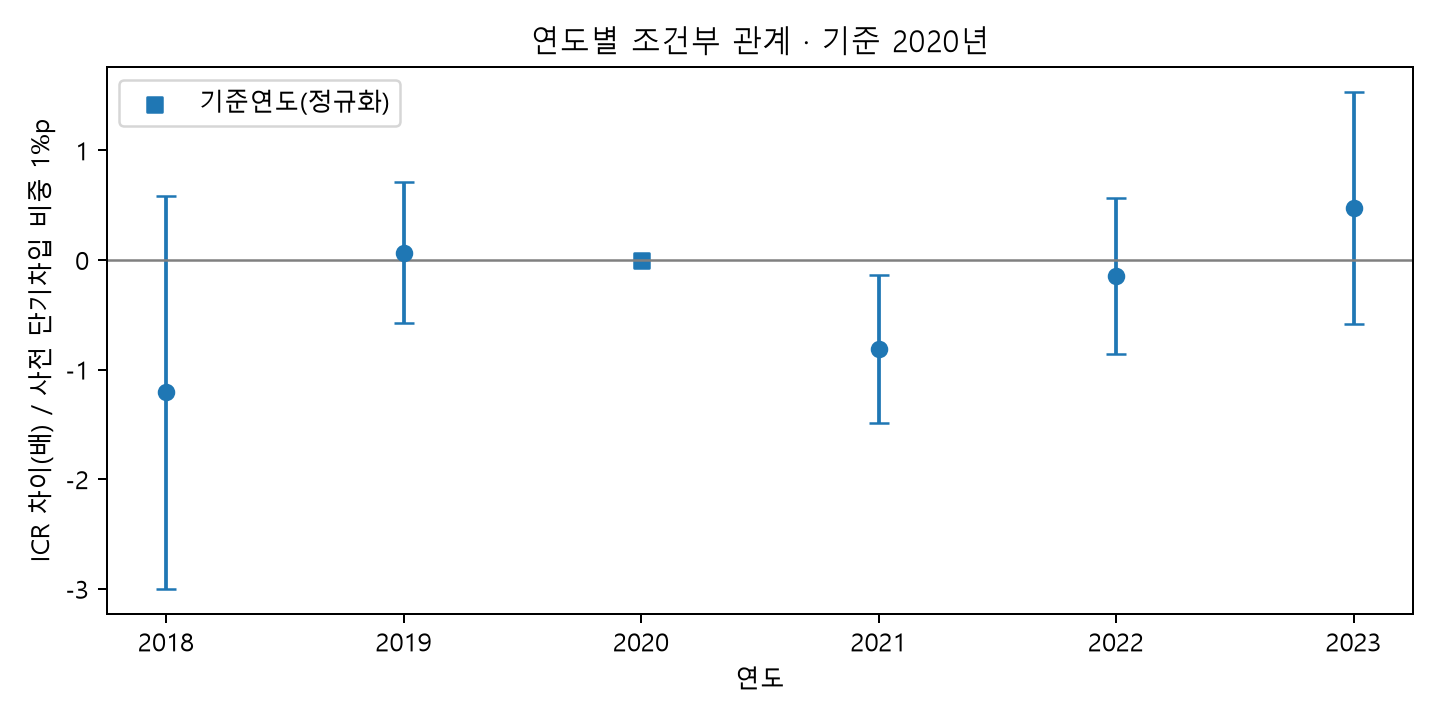

In [6]:
# 연도별 계수와 사전기간 공동검정
events = []
tests = []
for ref in [2020, 2019]:
    c = t.copy()
    terms = []
    for yr in sorted(c.year.unique()):
        if yr == ref:
            continue
        for var in ['E', 'L']:
            name = f'{var}_{yr}'
            c[name] = c[var] * (c.year == yr)
            terms.append(name)
    r = fit(f'Event_ref{ref}', c, terms)
    for term in terms:
        events.append({'ref': ref, 'term': term, 'beta': r.params[term], 'lo': r.conf_int().loc[term, 0], 'hi': r.conf_int().loc[term, 1]})
    for vv in [['E'], ['E', 'L']]:
        names = [f'{v}_{yr}' for yr in [2018, 2019, 2020] if yr != ref for v in vv]
        R = np.zeros((len(names), len(r.params)))
        for k, n in enumerate(names):
            R[k, list(r.params.index).index(n)] = 1
        w = r.wald_test(R, use_f=True, scalar=True)
        tests.append({'ref': ref, 'variables': '+'.join(vv), 'F': float(w.statistic), 'p': float(w.pvalue), 'restrictions': len(names)})
    e = pd.DataFrame([x for x in events if x['ref'] == ref and x['term'].startswith('E_')])
    e['year'] = e.term.str.split('_').str[-1].astype(int)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.errorbar(e.year, e.beta, yerr=[e.beta - e.lo, e.hi - e.beta], fmt='o', capsize=4)
    ax.scatter([ref], [0], marker='s', label='기준연도(정규화)')
    ax.axhline(0, color='gray', lw=1)
    ax.set(xlabel='연도', ylabel='ICR 차이(배) / 사전 단기차입 비중 1%p', title=f'연도별 조건부 관계 · 기준 {ref}년')
    ax.legend()
    fig.tight_layout()
    fig.savefig(BASE / f'figures/event_{ref}.png', dpi=180)
    plt.close(fig)
events = pd.DataFrame(events)
tests = pd.DataFrame(tests)
save(events, 'events')
save(tests, 'pretrend_tests')
display(tests)
np.testing.assert_allclose(tests[tests.ref==2020].p,tests[tests.ref==2019].p,atol=1e-8)
display(Image(filename=str(BASE/'figures/event_2020.png')))


### 출력에서 읽을 수 있는 것

ref가 2019에서 2020으로 바뀌어도 E 공동검정 p=0.403, E+L 공동검정 p=0.195는 같다. 기준연도를 달리 표현해도 같은 사전 차이를 검정했기 때문이다.

*2020년을 기준으로 읽는 연도별 관계*

## 6. 역사적 비교와 계수 차이
2015–17 사전 평균과 2018–19 후반을 비교한다. 금리변화 없는 평시 또는 독립 통제집단이 아니다. 각 구간별 업종·연도FE와 모든 기울기를 허용하는 결합회귀를 사용한다. 2018–19 관측이 양 구간에 중복되므로 같은 업종을 두 구간에 걸쳐 한 군집으로 묶는다. 440행은 독립된 440개 관측이 아니며 고유 업종×연도는 360개다. 단기차입 비중의 기간별 계수 차이는 금리만의 차이를 뜻하지 않는다.

In [7]:
# 과거 기간의 기본 모형 추정
fit('Historical_M2',h,['EP','LP'])

# 두 기간의 계수 차이 검정
# β_hist·EP_all + Δβ·EP_tight 로 재매개화: Δβ를 직접 추정한다.
z=pd.concat([h.assign(window='h'),t.assign(window='t')],ignore_index=True)
z['EP_delta'] = z.EP * (z.window == 't')
z['LP_delta'] = z.LP * (z.window == 't')
terms=['EP','LP','EP_delta','LP_delta','ET','LT']
X=pd.concat([z[terms],pd.get_dummies(z.window+':'+z.code,prefix='wi',dtype=float),pd.get_dummies(z.window+':'+z.year.astype(str),prefix='wy',dtype=float)],axis=1)
# 각 구간의 기준연도 한 열을 제거: 구간별 업종FE가 구간 상수를 포함한다.
X=X.drop(columns=['wy_h:2015','wy_t:2018']).astype(float)
assert np.linalg.matrix_rank(X)==X.shape[1]
model = sm.OLS(z.Y, X)
r = model.fit(cov_type='cluster', cov_kwds={'groups': z.code, 'use_correction': True, 'df_correction': True}, use_t=True)
np.testing.assert_allclose(r.params.EP+ r.params.EP_delta,fits['M2'][3].params.EP,atol=1e-8)
np.testing.assert_allclose(r.params.EP,fits['Historical_M2'][3].params.EP,atol=1e-8)
diff = pd.DataFrame([{'term': v, 'beta': r.params[v], 'se': r.bse[v], 'lo': r.conf_int().loc[v, 0], 'hi': r.conf_int().loc[v, 1], 'p': r.pvalues[v], 'N_stacked': len(z), 'N_unique': len(z.drop_duplicates(['code', 'year'])), 'G': 40} for v in ['EP_delta', 'LP_delta']])
save(diff, 'historical_difference')
display(diff)
stack_model = model
stack_result = r
stack_data = z


,term,beta,se,lo,hi,p,N_stacked,N_unique,G
0,EP_delta,0.131030,1.250219,-2.397776,2.659836,0.917067,440,360,40
1,LP_delta,0.389876,0.325136,-0.267774,1.047526,0.237718,440,360,40


### 출력에서 읽을 수 있는 것

EP_delta의 95% 구간은 −2.398~+2.660배다. 두 기간의 관계가 얼마나 다른지 폭넓은 값이 가능하다. N_stacked=440 중 고유 업종·연도는 N_unique=360이다.

- 과거 비교기간의 단기차입 계수를 먼저 추정했다. 그 값이 긴축기와 다른지는 이 한 번의 회귀로 판별할 수 없다.
- 이전 기간과 직접 비교 — 표의 EP_delta는 긴축기와 과거 비교기간의 단기차입 계수 차이다. +0.131배(p=0.917)여서 두 기간의 관계가 달랐다는 증거가 약하다.

## 7. 이자비용·영업이익 및 탐색적 완충관계
금액은 전기 총자산으로 나누고 ×100하여 % 단위로 보고한다. 이자비용/자산은 차입금리 자체가 아니며 부채량 변화도 포함한다. 두 회귀의 계수 차이는 ICR 기여도 분해가 아니다. M5는 사전 E·L을 40업종 평균으로 중심화하고 하위 기간항을 모두 유지한다. 상호작용이 유의하더라도 인과적 완충효과로 확정하지 않는다.

In [8]:
# 이자비용과 영업이익 별도 추정
for y in ['interest_asset', 'profit_asset']:
    fit('Component_' + y, t, m2, y)

# 유동성 결합항 추정
c = t.copy()
centers = c.drop_duplicates('code')[['E', 'L']].mean()
c['Ec'] = c.E - centers.E
c['Lc'] = c.L - centers.L
c['EP'] = c.Ec * c.Post
c['LP'] = c.Lc * c.Post
c['ET'] = c.Ec * (c.year == 2021)
c['LT'] = c.Lc * (c.year == 2021)
c['ELP'] = c.Ec * c.Lc * c.Post
c['ELT'] = c.Ec * c.Lc * (c.year == 2021)
fit('M5_exploratory',c,m2+['ELP','ELT'])
save(pd.DataFrame(rows).query('model.str.startswith("Component_") or model=="M5_exploratory"',engine='python'),'components_moderation')
display(pd.DataFrame(rows).query('(model.str.startswith("Component_") and term=="EP") or (model=="M5_exploratory" and term=="ELP")',engine='python'))


,model,outcome,term,beta,se,lo,hi,p,N,G
55,Component_interest_asset,interest_asset,EP,0.004257,0.010178,-0.016330,0.024844,0.678075,240,40
59,Component_profit_asset,profit_asset,EP,0.220447,0.233604,-0.252063,0.692956,0.351145,240,40
67,M5_exploratory,Y,ELP,-0.002557,0.015079,-0.033058,0.027943,0.866202,240,40


### 출력에서 읽을 수 있는 것

ELP는 단기차입과 유동성이 함께 높은 경우의 추가 관계다. 계수 −0.0026의 95% 구간은 −0.0331~+0.0279여서 완충 여부가 불확실하다.

- 사전 단기차입과 자산 대비 이자비용의 변화는 p=0.678, 자산 대비 영업이익의 변화는 p=0.351이었다. 이자 쪽과 이익 쪽 중 어느 한쪽에서 연결이 뚜렷하다는 근거가 약했다.
- M2에 단기차입과 유동성의 결합항을 추가했다. 그 계수는 −0.0026(p=0.866)으로, 유동성이 높을수록 단기차입의 불리한 관계가 약해졌다는 패턴을 확인하기 어려웠다.

## 8. 귀무제약 wild cluster bootstrap
MacKinnon·Nielsen·Webb(2023) §5–6에 따라 군집에 속한 업종 고정효과만 먼저 제거하고, 연도 효과와 다른 설명변수는 남긴다. WCR-S(type31)와 고전 WCR-C(type11)를 함께 기록한다. 삭제 군집에서 식별 안 되는 업종 더미를 그대로 jackknife에 넣지 않는다. Rademacher, 귀무 β=0, 9,999회, seed 고정. 패키지 p값의 모의오차는 최대 약 0.005다. 40군집에서도 업종 간 오차 독립 가정은 남고, 6개 연도로 연도 군집 추론을 정밀하게 보장할 수 없다.

In [9]:
# 업종별 재표집 함수 정의
def within_boot(model, groups, param, label):
    xx = pd.DataFrame(model.exog, columns=model.exog_names)
    yy = pd.Series(model.endog)
    gg = pd.Series(np.asarray(groups))
    xx = xx - xx.groupby(gg).transform('mean')
    yy = yy - yy.groupby(gg).transform('mean')
    xx = xx.loc[:, np.max(np.abs(xx), axis=0) > 1e-10]
    assert np.linalg.matrix_rank(xx) == xx.shape[1]
    mm = sm.OLS(yy, xx)
    np.testing.assert_allclose(mm.fit().params[param], model.fit().params[param], atol=1e-08)
    ans = []
    for variant in ['31', '11']:
        res = wildboottest(mm, param=param, cluster=pd.factorize(gg)[0], B=B, seed=SEED, bootstrap_type=variant, impose_null=True, weights_type='rademacher', show=False)
        ans.append({'model': label, 'term': param, 'bootstrap_type': variant, 'p_boot': float(res['p-value'].iloc[0]), 'B': B, 'seed': SEED})
    return ans

# 기본 계수 재검정
boot=[]
for label, param in [('M2', 'EP'), ('M2', 'LP'), ('M5_exploratory', 'ELP')]:
    d, terms, model, res = fits[label]
    boot.extend(within_boot(model, d.code, param, label))

# 기간 차이 재검정
# 결합모형 업종×구간 FE는 군집(업종)보다 세분화되어 있으므로 해당 FE를 제거한다.
xx = pd.DataFrame(stack_model.exog, columns=stack_model.exog_names)
yy = pd.Series(stack_model.endog)
g = z.window + ':' + z.code
xx = xx - xx.groupby(g).transform('mean')
yy = yy - yy.groupby(g).transform('mean')
xx = xx.loc[:, np.max(np.abs(xx), axis=0) > 1e-10]
mm = sm.OLS(yy, xx)
assert np.linalg.matrix_rank(xx) == xx.shape[1]
np.testing.assert_allclose(mm.fit().params.EP_delta,stack_result.params.EP_delta,atol=1e-8)
for variant in ['31','11']:
    rr=wildboottest(mm,param='EP_delta',cluster=pd.factorize(z.code)[0],B=B,seed=SEED,bootstrap_type=variant,impose_null=True,weights_type='rademacher',show=False)
    boot.append({'model':'Historical_difference','term':'EP_delta','bootstrap_type':variant,'p_boot':float(rr['p-value'].iloc[0]),'B':B,'seed':SEED})
boot = pd.DataFrame(boot)
save(boot, 'bootstrap')
display(boot)


,model,term,bootstrap_type,p_boot,B,seed
0,M2,EP,31,0.259126,9999,20261101
1,M2,EP,11,0.260026,9999,20261101
2,M2,LP,31,0.323032,9999,20261101
3,M2,LP,11,0.324032,9999,20261101
4,M5_exploratory,ELP,31,0.928293,9999,20261101
5,M5_exploratory,ELP,11,0.926393,9999,20261101
6,Historical_difference,EP_delta,31,0.906491,9999,20261101
7,Historical_difference,EP_delta,11,0.907891,9999,20261101


### 출력에서 읽을 수 있는 것

B=9999는 재표집 횟수이고 seed는 재현용 시작값이다. 결과를 읽을 열은 p_boot다.

- 같은 업종에 속하는 연도별 관측을 함께 다루는 부트스트랩 검정 함수를 정의했다.
- M2의 단기차입 항은 p=0.259, 유동성 항은 p=0.323, M5의 결합항은 p=0.928이었다. 검정 방식을 바꿔도 초기 가설에 대한 판단은 달라지지 않았다.
- 과거 기간과 긴축기의 단기차입 계수 차이도 같은 방식으로 검정했다. p=0.907로, 시기별 관계가 달라졌다고 보기 어려웠다.

## 9. 보고용 표·그림
40업종의 사전 재무특성, 사전·전환·사후 ICR 평균과 관측 변화량을 제공한다. 이 표를 업종별 금리 인과 민감도 순위로 해석하지 않는다. 그룹은 결과를 보고 임의로 묶지 않는다. 정의 미확정 반도체 관련 그룹 제외와 임의 업황 지수는 실행하지 않았다.

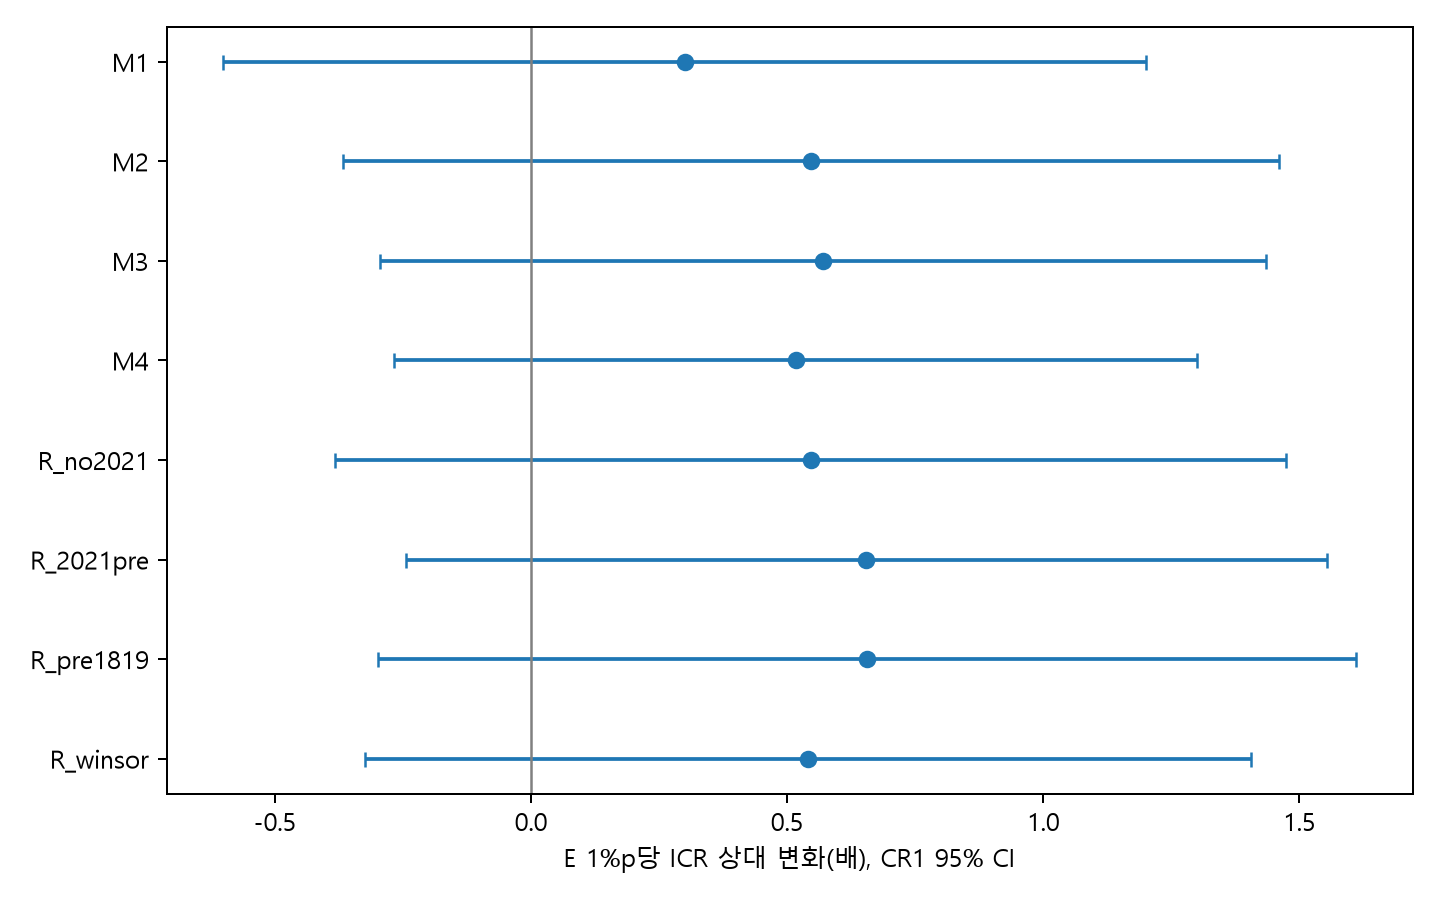

완료: 원본 수정 없음. 모든 결과는 tables/ 및 figures/에 저장. 본문 해석은 검토보고서 참고.


In [10]:
# 업종별 기간 평균 계산
industry=t.groupby(['code','industry']).agg(E=('E','first'),L=('L','first')).reset_index()
for label, years in [('ICR_pre', [2018, 2019, 2020]), ('ICR_transition', [2021]), ('ICR_post', [2022, 2023])]:
    av = t[t.year.isin(years)].groupby('code').Y.mean()
    industry[label] = industry.code.map(av)
industry['ICR_change'] = industry.ICR_post - industry.ICR_pre
save(industry, 'industry_descriptive')

# 사양별 추정치 그리기
allresults = pd.DataFrame(rows)
save(allresults, 'all_coefficients')
plot=allresults[(allresults.term=='EP') & allresults.model.isin(['M1','M2','M3','M4','R_no2021','R_2021pre','R_pre1819','R_winsor'])]
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(plot.beta, np.arange(len(plot)), xerr=[plot.beta - plot.lo, plot.hi - plot.beta], fmt='o', capsize=3)
ax.axvline(0, color='gray', lw=1)
ax.set_yticks(np.arange(len(plot)), plot.model)
ax.set_xlabel('E 1%p당 ICR 상대 변화(배), CR1 95% CI')
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(BASE / 'figures/specifications.png', dpi=180)
plt.close(fig)
display(Image(filename=str(BASE / 'figures/specifications.png')))
print('완료: 원본 수정 없음. 모든 결과는 tables/ 및 figures/에 저장. 본문 해석은 검토보고서 참고.')


### 출력에서 읽을 수 있는 것

점은 모형별 추정치이고 가로 또는 세로 오차선은 불확실성 구간이다. 같은 설명변수라도 결과변수의 단위가 바뀐 사양은 크기를 직접 비교할 수 없다.

- 업종마다 사전·전환·긴축기 평균 ICR을 따로 계산했다. 표의 변화량은 실제 기간평균 간 차이이므로 업종별 금리 효과 순위로 읽을 수 없다.
- 여러 사양의 단기차입 계수와 불확실성을 한 그림에서 비교하도록 저장했다.

*사양별 단기차입 추정치*

## 실행 결과 해석
M2 E×Post=+0.5459배, CR1 95% CI [−0.3681, 1.4599], p=0.2343, WCR-S p=0.2591. 사전 차입이 높은 업종일수록 더 악화된다는 가설을 지지하지 않는다. 효과 없음이나 차입의 이점도 입증하지 않는다.
M3·M4, 기간·E/L 사전평균·ICR 변환에서도 주 판단은 달라지지 않는다. M5 완충항의 WCR-S p=0.9283. 역사적 비교와의 계수차이는 0.1310, WCR-S p=0.9065. 영업이익·이자 부담 어느 경로도 확정할 충분한 정밀도를 얻지 못했다.
2020/2019 기준에서 같은 사전 귀무가설은 같은 공동검정 p값을 낸다. 이는 사전추세가 입증되었다는 뜻이 아니다. 관련 근거: [Roth(2022), 305–306쪽](https://www.jonathandroth.com/assets/files/roth_pretrends_testing.pdf), [MacKinnon 외(2023), §§5–6](https://onlinelibrary.wiley.com/doi/full/10.1002/jae.2969), [Zeldow·Hatfield(2021), §1.3.3](https://pmc.ncbi.nlm.nih.gov/articles/PMC8522571/). 짧은 본문 인용·적용한계는 동봉 HTML에 기록했다.
단기차입 항목구성 및 산업별 ICR 집계의 공식 정의는 추가 확인 필요. 현재 산식을 유지했으며 미확인 정의를 보완했다고 주장하지 않는다.